# Barrier sets give the same trend
Mean olefin length vs temperature at 50 bar for the three barrier sets: `tetra` (one set for all chains, Flory-Schulz-like), `bep` (BEP extrapolation) and `legacy` (original list).

Same for all: pressure, catalytic site amount (`CAT` = 1e-2 per unit cell), time (1 h), pocket crowding with the default strength. Only the barrier set differs. The reduced network is valid over the whole range at 50 bar (`km.network_consistency`). Absolute values differ (BEP gives shorter chains at low T); the trend is the same: a U-shape in batch, a monotonic rise in flow.

In [1]:
import sys
sys.path.insert(0, '../scripts')
import warnings; warnings.filterwarnings('ignore')
import km_common as km
import pandas as pd
import matplotlib.pyplot as plt

P = 50                                   # bar, same for all
T = list(range(300, 521, 20))
assert all(km.network_consistency(t, P)[0] for t in T)
VARIANTS = {'tetra': dict(elim_map='tetra'),
            'bep': dict(elim_map='bep'),
            'legacy': dict(elim_map='legacy')}
CASES = {'batch, no diffusion limit': ('batch', None),
         'batch, 1000 um': ('batch', 1e6),
         'flow, 1000 um': ('flow', 1e6)}

In [2]:
rows = []
for case, (mode, size) in CASES.items():
    for name, kw in VARIANTS.items():
        for t in T:
            dist, _ = km.simulate(t, P, mode=mode, particle_nm=size, model='corrected', hours=1.0, n_steps=300,
                                  crowding='pocket', check_network=None, **kw)
            rows.append((case, name, t, km.mean_length(dist)))
res = pd.DataFrame(rows, columns=['case', 'variant', 'T', 'mean_n'])
res.pivot_table(index=['case', 'variant'], columns='T', values='mean_n').round(1)

T                                   300   320   340   360   380  400  420  \
case                      variant                                           
batch, 1000 um            bep       5.6   6.8   5.7   5.6   5.7  5.8  6.0   
                          legacy   14.3  11.6   8.9   8.3   8.4  8.5  8.5   
                          tetra    14.3  11.2   8.5   8.0   8.0  8.0  8.1   
batch, no diffusion limit bep       5.7   7.4   7.6   6.4   5.6  5.0  4.8   
                          legacy   14.9  15.7  15.9  13.7  10.7  8.6  7.4   
                          tetra    14.8  15.6  15.0  11.9   9.3  7.6  6.7   
flow, 1000 um             bep       4.8   4.5   4.8   5.5   6.3  7.0  7.6   
                          legacy   13.9   9.3   7.6   7.7   8.0  8.3  8.6   
                          tetra    14.1   9.1   7.2   7.3   7.6  7.9  8.3   

T                                   440   460   480   500   520  
case                      variant                                
batch, 1000 um            bep       7.6  12.5  14.0  14.6  14.2  
                          legacy    9.1  12.7  14.1  14.7  14.3  
                          tetra    10.0  13.6  14.6  15.1  14.9  
batch, no diffusion limit bep       5.2   9.2  12.8  11.3   9.6  
                          legacy    7.5  11.9  13.4  12.2  10.9  
                          tetra     8.8  14.6  14.2  13.4  12.3  
flow, 1000 um             bep       8.2   8.7   9.2   9.7  10.0  
                          legacy    8.9   9.2   9.5  10.0  10.2  
                          tetra     8.6   8.9   9.3   9.7  10.0

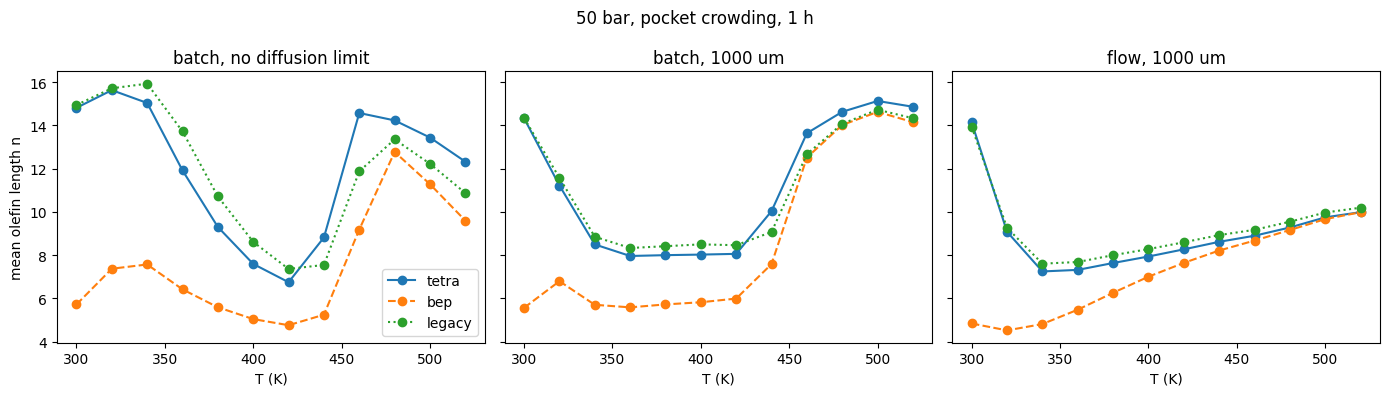

In [3]:
styles = {'tetra': ('C0', '-'), 'bep': ('C1', '--'), 'legacy': ('C2', ':')}
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (case, g) in zip(axs, res.groupby('case', sort=False)):
    for name, h in g.groupby('variant', sort=False):
        ax.plot(h['T'], h['mean_n'], color=styles[name][0], ls=styles[name][1], marker='o', label=name)
    ax.set_title(case); ax.set_xlabel('T (K)')
axs[0].set_ylabel('mean olefin length n'); axs[0].legend()
fig.suptitle(f'{P} bar, pocket crowding, 1 h')
plt.tight_layout()